# Hierarchical Clustering

Hierarchical Clustering is an unsupervised machine learning algorithm that groups similar observations into clusters by building a hierarchy of clusters.

It does not require the number of clusters to be specified before constructing the hierarchy. The relationships between observations are represented using a tree-like structure called a **dendrogram**.

There are two main approaches:

- **Agglomerative:** A bottom-up approach that progressively merges smaller clusters.
- **Divisive:** A top-down approach that progressively splits larger clusters.

This project focuses on Agglomerative Hierarchical Clustering.

## How It Works

1. Each observation initially forms its own cluster.
2. Distances between clusters are calculated.
3. The two closest clusters are merged.
4. Cluster distances are recalculated using a linkage method.
5. The process continues until a stopping condition is reached.
6. A dendrogram can be used to determine the final number of clusters.

## Key Concepts

- **Distance Metrics:** Measure dissimilarity between observations, such as Euclidean and Manhattan distance.
- **Linkage Methods:** Determine how distances between clusters are calculated.
- **Dendrogram:** Visualizes the hierarchy and merging process.
- **Agglomerative Clustering:** Progressively merges clusters.
- **Divisive Clustering:** Progressively splits clusters.

### Common Linkage Methods

- **Single:** Minimum distance between observations in two clusters.
- **Complete:** Maximum distance between observations in two clusters.
- **Average:** Average pairwise distance between two clusters.
- **Ward:** Minimizes the increase in within-cluster variance when merging clusters.

## Mathematical Formulations

**1. Euclidean Distance**
$$
d(A,B)=\sqrt{\sum_{i=1}^{n}(A_i-B_i)^2}
$$
**2. Manhattan Distance**
$$
d(A,B)=\sum_{i=1}^{n}|A_i-B_i|
$$
**3. Single Linkage**
$$
D(A,B)=\min_{a\in A,b\in B}d(a,b)
$$
**4. Complete Linkage**
$$
D(A,B)=\max_{a\in A,b\in B}d(a,b)
$$
**5. Average Linkage**

$$
D(A,B)=\frac{1}{|A||B|}
\sum_{a\in A}\sum_{b\in B}d(a,b)
$$
**6. Ward Linkage**
$$
\Delta(A,B)=
\frac{|A||B|}{|A|+|B|}
\|\mu_A-\mu_B\|^2
$$
## Assumptions and Considerations

- Feature scaling is important because clustering relies on distance calculations.
- The choice of distance metric and linkage method affects cluster formation.
- Outliers can influence clustering results.
- Hierarchical clustering can be computationally expensive for large datasets.
- Agglomerative merging is irreversible.

## Advantages

- Does not require specifying the number of clusters initially.
- Dendrograms provide interpretable visualizations.
- Supports different distance metrics and linkage methods.
- Can reveal nested relationships within data.

## Limitations

- Computationally expensive for large datasets.
- Sensitive to distance and linkage choices.
- Early merging decisions cannot be reversed.
- Outliers can affect cluster formation.

## Objectives

- Understand hierarchical clustering.
- Explore different linkage methods.
- Visualize cluster relationships using dendrograms.
- Determine an appropriate number of clusters.
- Train and evaluate an Agglomerative Clustering model.

In [75]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import (silhouette_score,davies_bouldin_score,calinski_harabasz_score)
import warnings
warnings.filterwarnings('ignore')

In [76]:
# load dataset
mall_df = pd.read_csv("../Datasets/Mall_Customers.csv")

print(mall_df.shape)
mall_df.head()

(200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [77]:
mall_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [78]:
mall_df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [79]:
mall_df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [80]:
mall_df.duplicated().sum()

np.int64(0)

In [81]:
# Preprocessing
X = mall_df[['Annual Income (k$)', 'Spending Score (1-100)']].copy()

X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [82]:
# scaling
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled,columns=X.columns,index=X.index)

X_scaled.head()

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


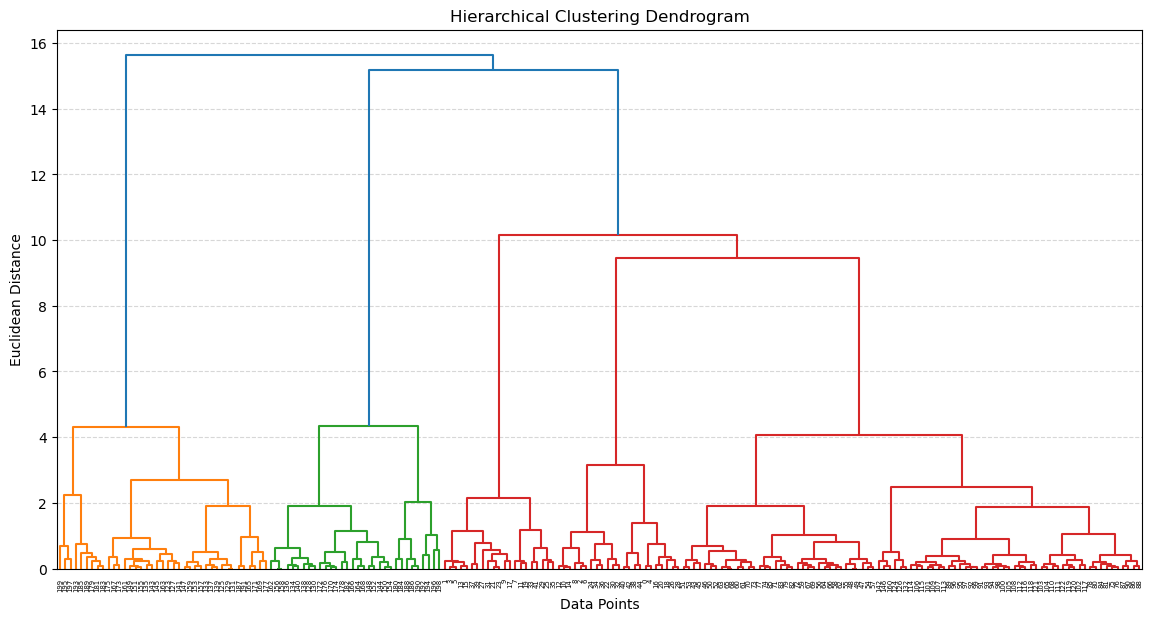

In [83]:
# Modelling
# linkage matrix
linked = linkage(X_scaled, method='ward')
plt.figure(figsize=(14, 7)) # dendogram

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

In [84]:
# Modelling
hc = AgglomerativeClustering(n_clusters=5,metric='euclidean',linkage='ward')

clusters = hc.fit_predict(X_scaled)

mall_df['Cluster'] = clusters

mall_df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,3
2,3,Female,20,16,6,4
3,4,Female,23,16,77,3
4,5,Female,31,17,40,4


In [85]:
# cluster distribution
mall_df['Cluster'].value_counts().sort_index()

Cluster
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64

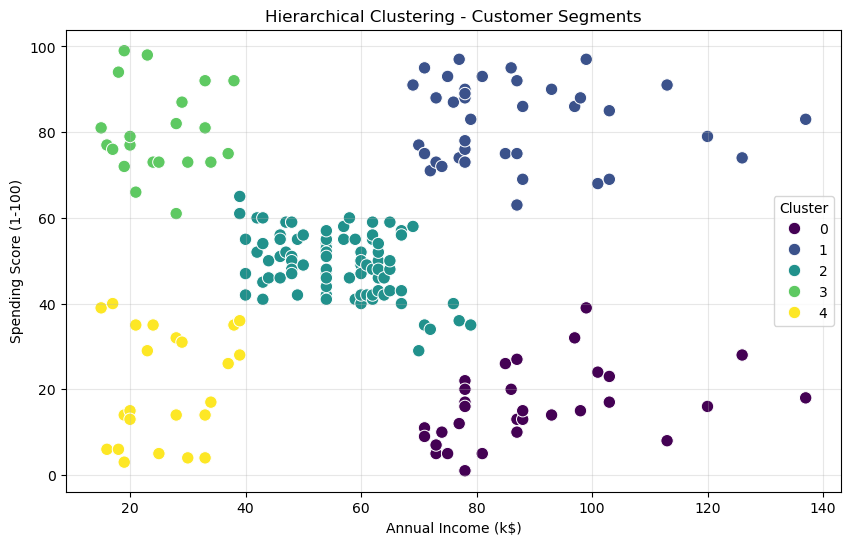

In [86]:
# cluster visualization
plt.figure(figsize=(10, 6))

sns.scatterplot(data=mall_df,x='Annual Income (k$)',y='Spending Score (1-100)',hue='Cluster',palette='viridis',s=80)

plt.title('Hierarchical Clustering - Customer Segments')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.grid(alpha=0.3)

plt.show()

In [87]:
# Evaluation
silhouette = silhouette_score(X_scaled, clusters)
davies_bouldin = davies_bouldin_score(X_scaled, clusters)
calinski_harabasz = calinski_harabasz_score(X_scaled, clusters)

print("Silhouette Score:", silhouette)
print("Davies-Bouldin Index:", davies_bouldin)
print("Calinski-Harabasz Score:", calinski_harabasz)

Silhouette Score: 0.5538089226688662
Davies-Bouldin Index: 0.5778621190740154
Calinski-Harabasz Score: 244.41032586596822


In [88]:
results = []

for k in range(2, 11):
    hc = AgglomerativeClustering(n_clusters=k,metric='euclidean',linkage='ward')

    labels = hc.fit_predict(X_scaled)

    results.append({
        'Clusters': k,
        'Silhouette Score': silhouette_score(X_scaled, labels),
        'Davies-Bouldin Index': davies_bouldin_score(X_scaled, labels),
        'Calinski-Harabasz Score': calinski_harabasz_score(X_scaled, labels)
    })

hc_results = pd.DataFrame(results)

hc_results

,Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,2,0.384234,0.854356,86.961556
1,3,0.461048,0.707287,143.779562
2,4,0.492551,0.670718,169.679831
3,5,0.553809,0.577862,244.410326
4,6,0.538676,0.644868,233.308806
5,7,0.519795,0.713283,237.258506
6,8,0.430862,0.777741,250.588294
7,9,0.437690,0.776487,252.929359
8,10,0.433901,0.766997,252.517220


In [89]:
# cluster averages
cluster_profiles = mall_df.groupby('Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean().round(2)

cluster_profiles

,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,89.41,15.59
1,86.54,82.13
2,55.81,49.13
3,25.10,80.05
4,26.30,20.91


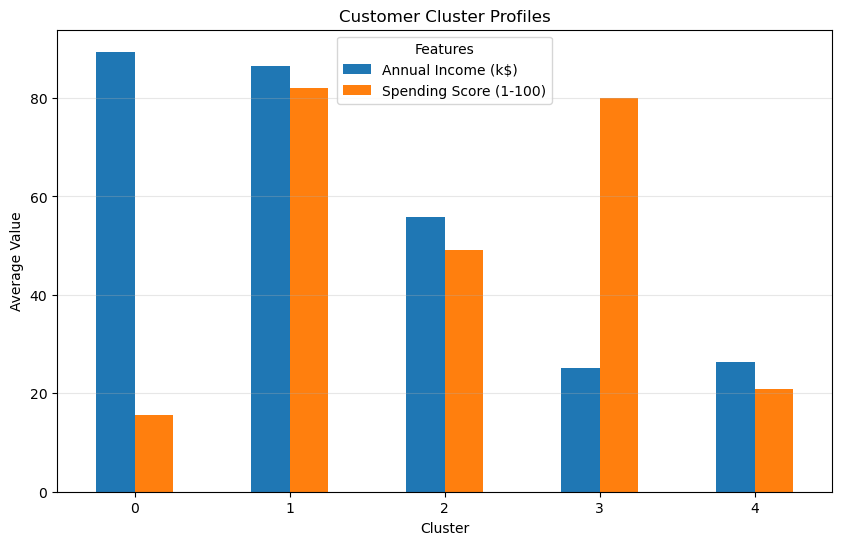

In [90]:
cluster_profiles.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Customer Cluster Profiles')
plt.xlabel('Cluster')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.legend(title='Features')
plt.grid(axis='y', alpha=0.3)

plt.show()

In [91]:
# different linkage
linkage_methods = ['ward', 'complete', 'average', 'single']

linkage_results = []

for method in linkage_methods:

    hc = AgglomerativeClustering(
        n_clusters=5,
        metric='euclidean',
        linkage=method
    )

    labels = hc.fit_predict(X_scaled)

    linkage_results.append({
        'Linkage': method,
        'Silhouette Score': silhouette_score(X_scaled, labels),
        'Davies-Bouldin Index': davies_bouldin_score(X_scaled, labels),
        'Calinski-Harabasz Score': calinski_harabasz_score(X_scaled, labels)
    })

linkage_df = pd.DataFrame(linkage_results)

linkage_df

,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,ward,0.553809,0.577862,244.410326
1,complete,0.553112,0.568015,247.208226
2,average,0.479426,0.643251,143.589171
3,single,0.275800,0.423064,5.646955


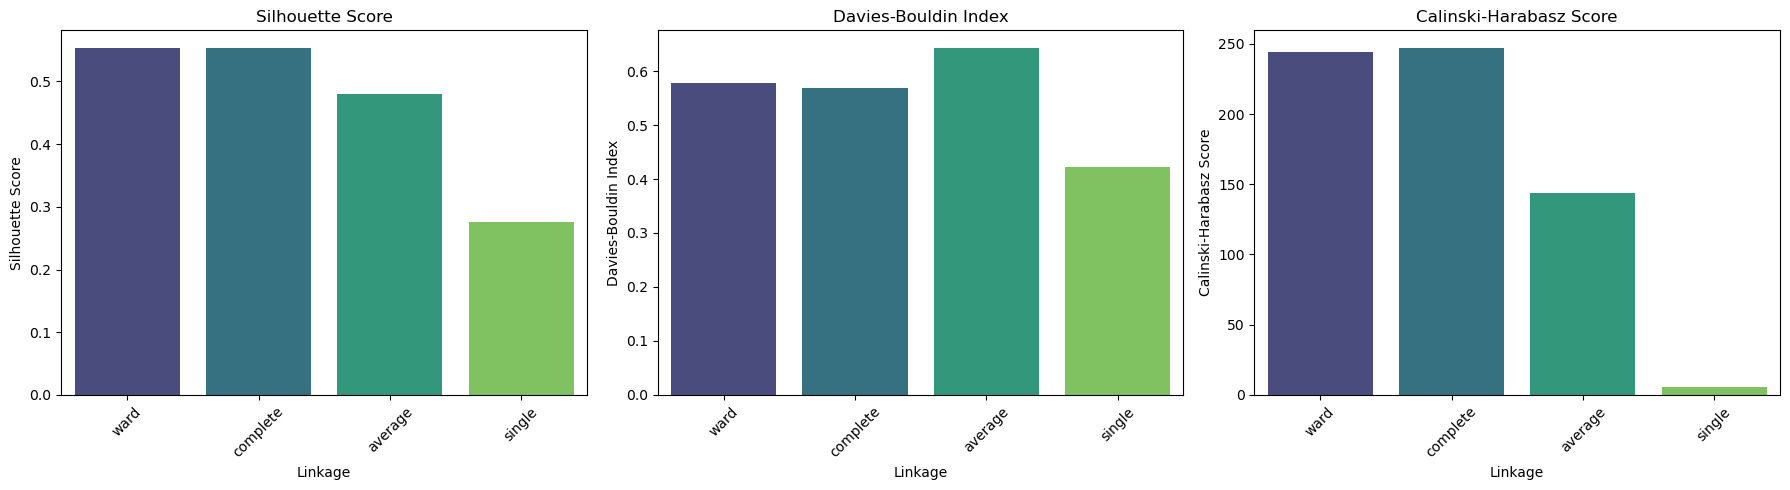

In [92]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = [
    'Silhouette Score',
    'Davies-Bouldin Index',
    'Calinski-Harabasz Score'
]

for ax, metric in zip(axes, metrics):
    sns.barplot(data=linkage_df,x='Linkage',y=metric,ax=ax,hue='Linkage',palette='viridis',legend=False)

    ax.set_title(metric)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

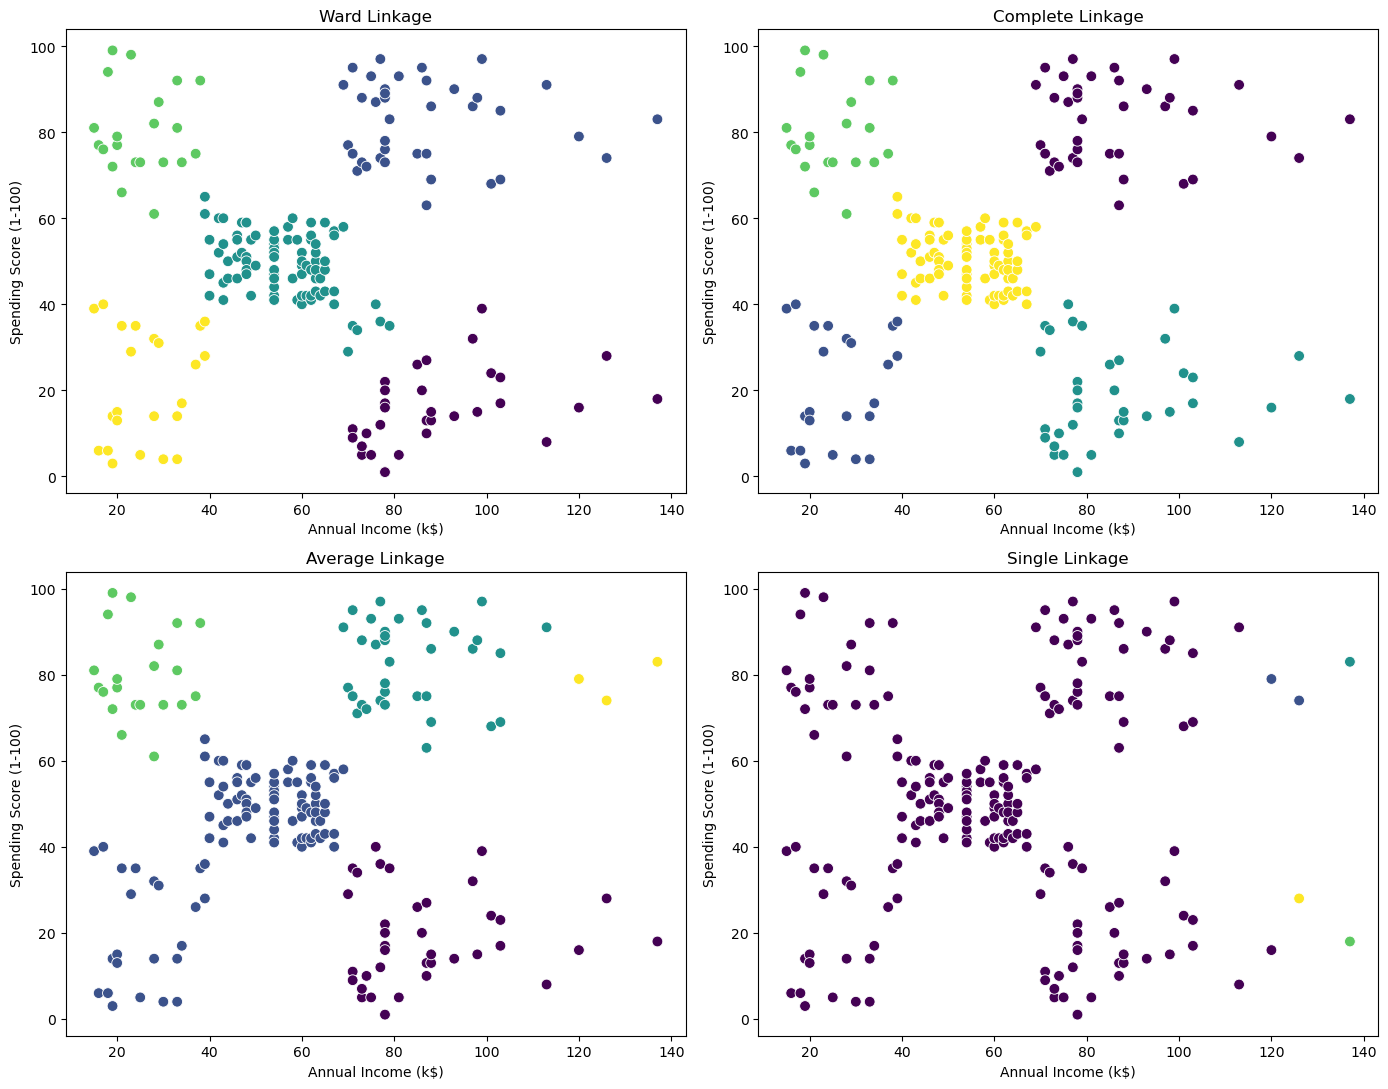

In [93]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, method in zip(axes.flat, linkage_methods):

    hc = AgglomerativeClustering(
        n_clusters=5,
        metric='euclidean',
        linkage=method
    )

    labels = hc.fit_predict(X_scaled)

    sns.scatterplot(x=X['Annual Income (k$)'],y=X['Spending Score (1-100)'],hue=labels,palette='viridis',s=60,ax=ax,legend=False)

    ax.set_title(f'{method.title()} Linkage')
    ax.set_xlabel('Annual Income (k$)')
    ax.set_ylabel('Spending Score (1-100)')

plt.tight_layout()
plt.show()

In [94]:
for method in linkage_methods:

    hc = AgglomerativeClustering(
        n_clusters=5,
        metric='euclidean',
        linkage=method
    )

    labels = hc.fit_predict(X_scaled)

    print(f"\n{method.title()} Linkage")
    print(pd.Series(labels).value_counts().sort_index())


Ward Linkage
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64

Complete Linkage
0    39
1    23
2    38
3    21
4    79
Name: count, dtype: int64

Average Linkage
0     38
1    102
2     36
3     21
4      3
Name: count, dtype: int64

Single Linkage
0    195
1      2
2      1
3      1
4      1
Name: count, dtype: int64


## synthetic dataset

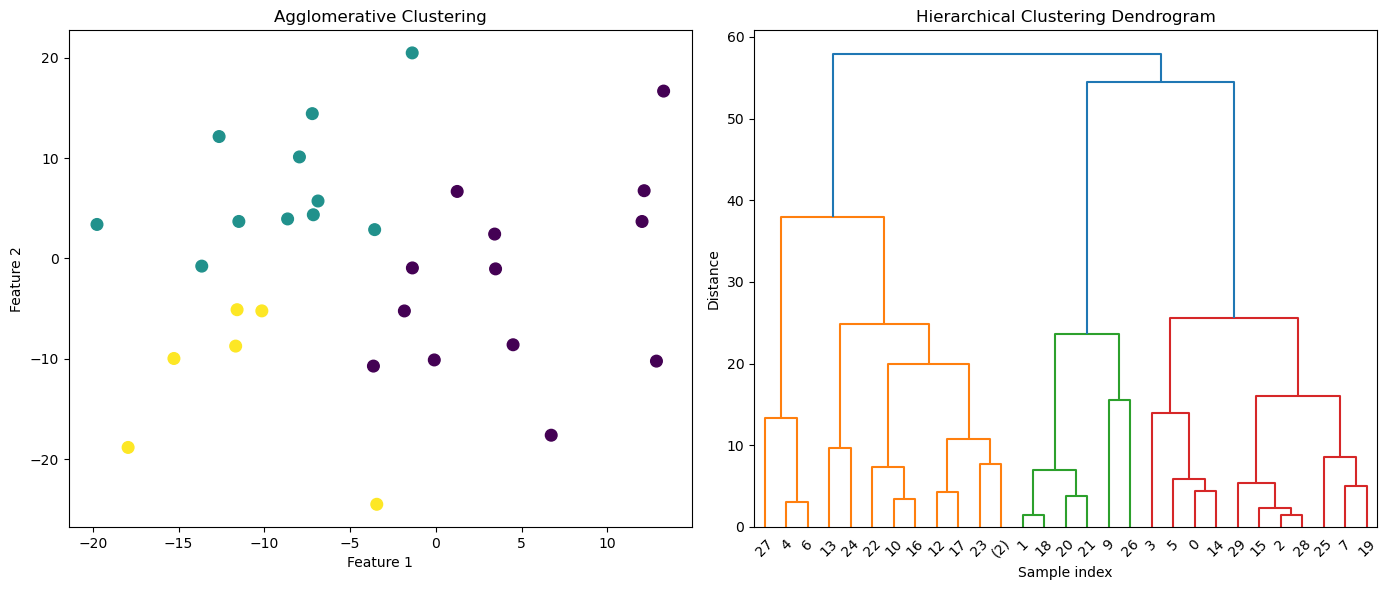

In [95]:
# Agglomerative
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram
from sklearn.datasets import make_blobs

X, _ = make_blobs(n_samples=30, centers=3, cluster_std=10, random_state=42)

clustering = AgglomerativeClustering(n_clusters=3)
labels = clustering.fit_predict(X)

agg = AgglomerativeClustering(distance_threshold=0,n_clusters=None,compute_distances=True)
agg.fit(X)


def plot_dendrogram(model, **kwargs):
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)

    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]).astype(float)
    dendrogram(linkage_matrix, **kwargs)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=70)
ax1.set_title("Agglomerative Clustering")
ax1.set_xlabel("Feature 1")
ax1.set_ylabel("Feature 2")

plt.sca(ax2)
plot_dendrogram(agg, truncate_mode='level', p=5)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Sample index")
plt.ylabel("Distance")

plt.tight_layout()
plt.show()

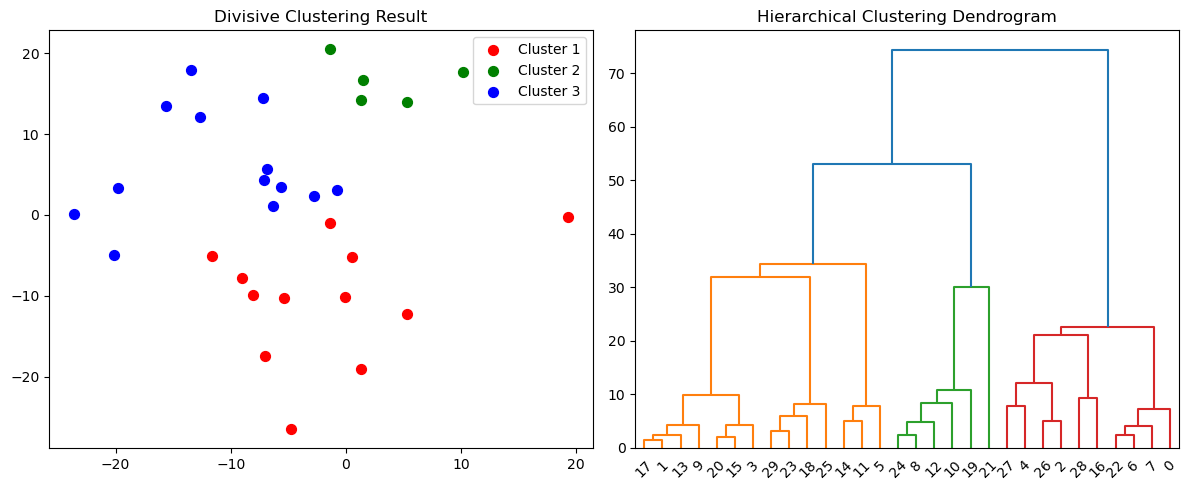

In [96]:
# Divisive 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from scipy.cluster.hierarchy import dendrogram, linkage

X, _ = make_blobs(n_samples=30, centers=5, cluster_std=10, random_state=42)


def divisive_clustering(data, max_clusters=3):
    clusters = [data]
    while len(clusters) < max_clusters:
        cluster_to_split = max(clusters, key=lambda x: len(x))
        clusters.remove(cluster_to_split)

        kmeans = KMeans(n_clusters=2, random_state=42).fit(cluster_to_split)
        cluster1 = cluster_to_split[kmeans.labels_ == 0]
        cluster2 = cluster_to_split[kmeans.labels_ == 1]

        clusters.extend([cluster1, cluster2])
    return clusters


clusters = divisive_clustering(X, max_clusters=3)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
colors = ['r', 'g', 'b', 'c', 'm', 'y']
for i, cluster in enumerate(clusters):
    plt.scatter(cluster[:, 0], cluster[:, 1], s=50,
                c=colors[i], label=f'Cluster {i+1}')
plt.title('Divisive Clustering Result')
plt.legend()

linked = linkage(X, method='ward')

plt.subplot(1, 2, 2)
dendrogram(linked, orientation='top',
           distance_sort='descending', show_leaf_counts=True)
plt.title('Hierarchical Clustering Dendrogram')

plt.tight_layout()
plt.show()

In [97]:
# Agglomerative Clustering
data = pd.read_csv("../Datasets/CC-GENERAL.csv")

data.drop('CUST_ID', axis=1, inplace=True)

data.fillna(method='ffill', inplace=True)

print(data.shape)
data.head()

(8950, 17)


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,627.284787,0.000000,12
4,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [98]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 17 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   BALANCE                           8950 non-null   float64
 1   BALANCE_FREQUENCY                 8950 non-null   float64
 2   PURCHASES                         8950 non-null   float64
 3   ONEOFF_PURCHASES                  8950 non-null   float64
 4   INSTALLMENTS_PURCHASES            8950 non-null   float64
 5   CASH_ADVANCE                      8950 non-null   float64
 6   PURCHASES_FREQUENCY               8950 non-null   float64
 7   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 8   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 9   CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 10  CASH_ADVANCE_TRX                  8950 non-null   int64  
 11  PURCHASES_TRX                     8950 non-null   int64  
 12  CREDIT

In [99]:
data.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.394205,1733.143852,865.225790,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.616165,2895.063757,2376.929826,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.488256,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.096808,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,815.375602,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


In [100]:
# missing values
data.isnull().sum()

BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              0
CASH_ADVANCE_TRX                    0
PURCHASES_TRX                       0
CREDIT_LIMIT                        0
PAYMENTS                            0
MINIMUM_PAYMENTS                    0
PRC_FULL_PAYMENT                    0
TENURE                              0
dtype: int64

In [101]:
# scaling & normalization
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.preprocessing import normalize
X = data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_normalized = normalize(X_scaled)

X_normalized = pd.DataFrame(X_normalized)

In [102]:
# reduce many columns features ..PCA
from sklearn.decomposition import PCA
pca = PCA(n_components = 2)
X_principal = pca.fit_transform(X_normalized)
X_principal = pd.DataFrame(X_principal)
X_principal.columns = ['P1', 'P2']

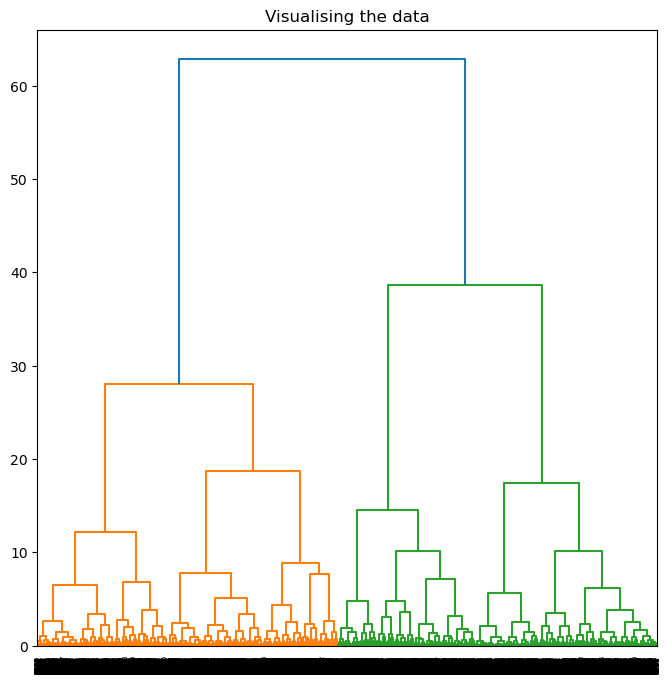

In [103]:
# dendrograms
import scipy.cluster.hierarchy as shc
plt.figure(figsize =(8, 8))
plt.title('Visualising the data')
Dendrogram = shc.dendrogram((shc.linkage(X_principal, method ='ward')))

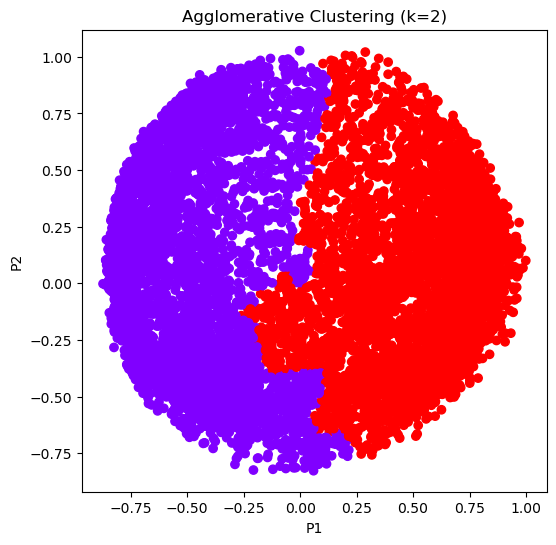

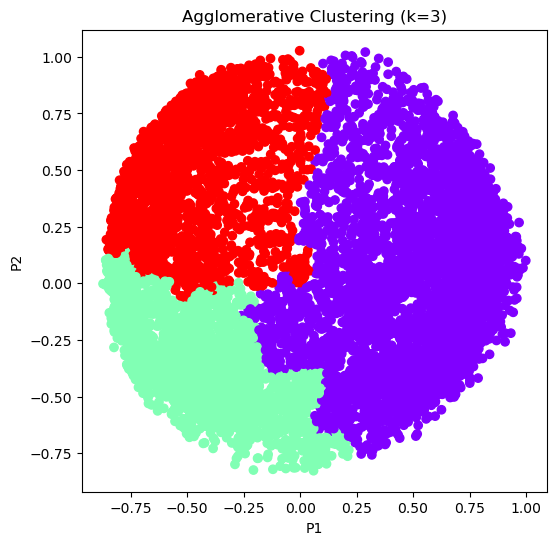

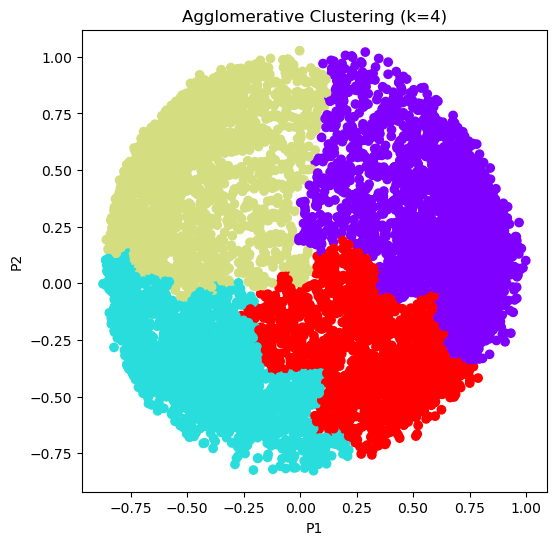

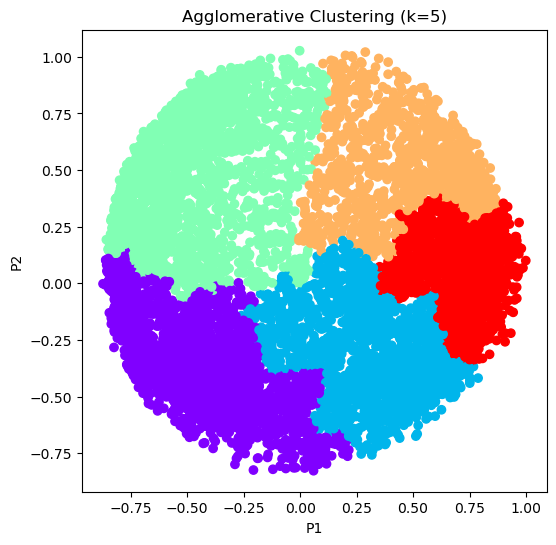

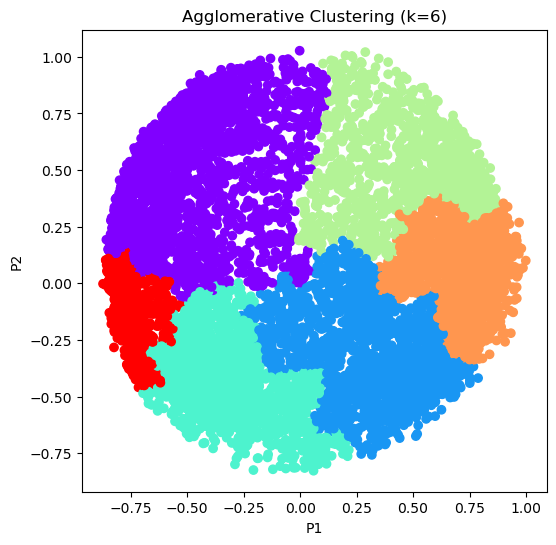

In [104]:
for k in range(2, 7):  # Try values from 2 to 6
    model = AgglomerativeClustering(n_clusters=k)
    labels = model.fit_predict(X_principal)

    plt.figure(figsize=(6, 6))
    plt.scatter(X_principal['P1'], X_principal['P2'], c=labels, cmap='rainbow')
    plt.title(f'Agglomerative Clustering (k={k})')
    plt.xlabel('P1')
    plt.ylabel('P2')
    plt.show()

In [105]:
# Evaluation
k = [2, 3, 4, 5, 6]

silhouette_scores = []
silhouette_scores.append(
        silhouette_score(X_principal, ac2.fit_predict(X_principal)))
silhouette_scores.append(
        silhouette_score(X_principal, ac3.fit_predict(X_principal)))
silhouette_scores.append(
        silhouette_score(X_principal, ac4.fit_predict(X_principal)))
silhouette_scores.append(
        silhouette_score(X_principal, ac5.fit_predict(X_principal)))
silhouette_scores.append(
        silhouette_score(X_principal, ac6.fit_predict(X_principal)))

plt.bar(k, silhouette_scores)
plt.xlabel('Number of clusters', fontsize = 20)
plt.ylabel('S(i)', fontsize = 20)
plt.show()

NameError: name 'ac2' is not defined

## Iris

In [107]:
# load dataset
from sklearn.datasets import load_iris

iris = load_iris()

iris_df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

print(iris_df.shape)
iris_df.head()

(150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [108]:
iris_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


In [109]:
iris_df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [110]:
iris_df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

In [111]:
X_iris = iris_df.copy()

X_iris.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

In [112]:
# preprocessing
scaler_iris = StandardScaler()

X_iris_scaled = scaler_iris.fit_transform(X_iris)

X_iris_scaled = pd.DataFrame(X_iris_scaled,columns=X_iris.columns)

X_iris_scaled.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


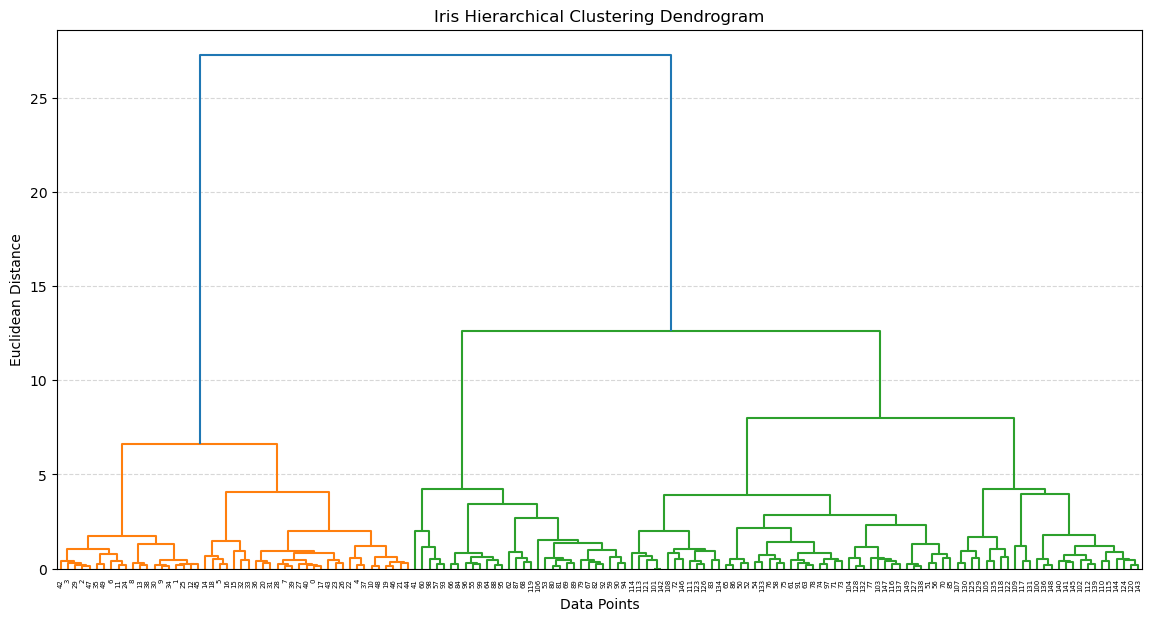

In [113]:
# dendrogram
linked_iris = linkage(X_iris_scaled, method='ward')

plt.figure(figsize=(14, 7))

dendrogram(linked_iris)

plt.title("Iris Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

In [114]:
# Modelling
hc_iris = AgglomerativeClustering(n_clusters=3,metric='euclidean',linkage='ward')

iris_clusters = hc_iris.fit_predict(X_iris_scaled)

iris_df['Cluster'] = iris_clusters

iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1


In [115]:
# cluster distribution
iris_df['Cluster'].value_counts().sort_index()

Cluster
0    71
1    49
2    30
Name: count, dtype: int64

In [116]:
# evaluation
iris_silhouette = silhouette_score(X_iris_scaled, iris_clusters)

iris_db = davies_bouldin_score(X_iris_scaled, iris_clusters)

iris_ch = calinski_harabasz_score(X_iris_scaled, iris_clusters)

print("Silhouette Score:", iris_silhouette)
print("Davies-Bouldin Index:", iris_db)
print("Calinski-Harabasz Score:", iris_ch)

Silhouette Score: 0.446689041028591
Davies-Bouldin Index: 0.803466530287675
Calinski-Harabasz Score: 222.7191638221536


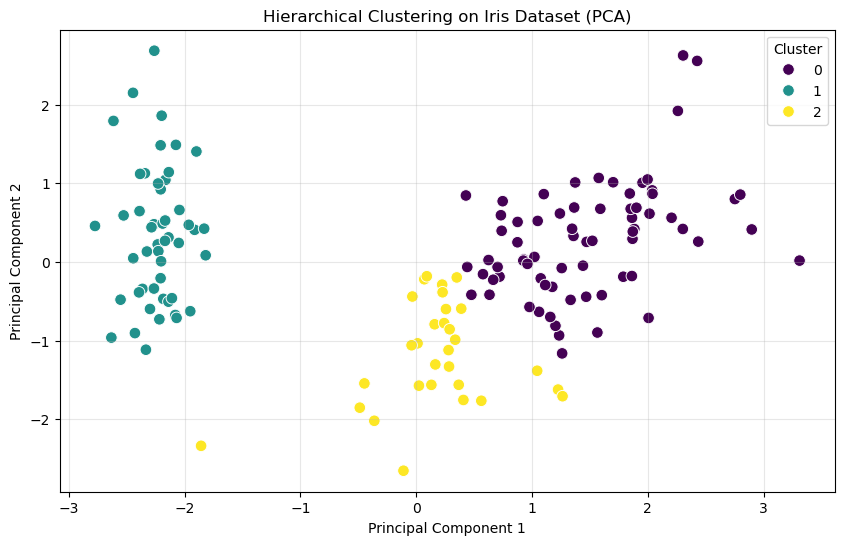

In [117]:
# PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

iris_pca = pca.fit_transform(X_iris_scaled)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=iris_pca[:, 0],
    y=iris_pca[:, 1],
    hue=iris_clusters,
    palette='viridis',
    s=70
)

plt.title("Hierarchical Clustering on Iris Dataset (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)

plt.show()

In [118]:
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.72962445 0.22850762]
Total explained variance: 0.9581320720000162


### Conclusion


Principal Component Analysis (PCA) was used to reduce the four Iris features into two principal components for visualization.

PC1: Explains 72.96% of the variance.

PC2: Explains 22.85% of the variance.

Total explained variance: 95.81%.

The two components retain most of the original dataset's variance, providing a useful two-dimensional representation of the clusters.

Hierarchical Clustering was applied to the Iris dataset using Agglomerative Clustering with Ward linkage and three clusters.

The model achieved:
- **Silhouette Score:** 0.4467
- **Davies-Bouldin Index:** 0.8035
- **Calinski-Harabasz Score:** 222.72
PCA reduced the four original features to two principal components while retaining 95.81% of the total variance, allowing the cluster assignments to be visualized in two dimensions.

The results demonstrate that Hierarchical Clustering can identify meaningful groupings in the Iris dataset, although some overlap exists between clusters.

Overall, the experiment demonstrates the application of hierarchical clustering, dendrogram analysis, cluster evaluation and dimensionality reduction on a real-world dataset.